In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [5]:
df = pd.read_csv("../data/Hanoi_temp_10_years.csv", parse_dates=["datetime"])
series = df.set_index("datetime")["temp"].asfreq("D")  
values = series.values

In [6]:
n = len(values)
train_end = int(n * 0.70)   
val_end = int(n * 0.85) 

In [7]:
scaler = MinMaxScaler()
scaler.fit(values[:train_end].reshape(-1, 1))   
scaled = scaler.transform(values.reshape(-1, 1)).flatten()

In [8]:
WINDOW = 30  

def make_windows(data, window):
    X, y = [], []
    for i in range(len(data) - window):
        X.append(data[i : i + window])
        y.append(data[i + window])
    X = np.array(X)[..., np.newaxis]   
    y = np.array(y)
    return X, y



In [9]:
X, y = make_windows(scaled, WINDOW)

In [10]:
target_idx = np.arange(WINDOW, len(scaled))
train_mask = target_idx < train_end
val_mask = (target_idx >= train_end) & (target_idx < val_end)
test_mask = target_idx >= val_end

In [11]:
X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

In [12]:
model = keras.Sequential([
    keras.Input(shape=(WINDOW, 1)),
    keras.layers.LSTM(64),
    keras.layers.Dense(1),
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss="mse", metrics=["mae"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 64)                  │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

In [14]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1,
)

Epoch 1/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - loss: 0.0347 - mae: 0.1239 - val_loss: 0.0087 - val_mae: 0.0729
Epoch 2/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.0083 - mae: 0.0716 - val_loss: 0.0081 - val_mae: 0.0699
Epoch 3/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - loss: 0.0079 - mae: 0.0707 - val_loss: 0.0079 - val_mae: 0.0689
Epoch 4/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - loss: 0.0077 - mae: 0.0696 - val_loss: 0.0076 - val_mae: 0.0684
Epoch 5/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - loss: 0.0076 - mae: 0.0691 - val_loss: 0.0079 - val_mae: 0.0682
Epoch 6/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - loss: 0.0074 - mae: 0.0681 - val_loss: 0.0075 - val_mae: 0.0692
Epoch 7/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - loss: 0.0069 - mae: 0.0662 - val_loss: 0.0070 - val_mae: 0.0661
Epoch 8/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - loss: 0.0067 - mae: 0.0650 - val_loss: 0.0067 - val_mae: 0.0631
Epoch 9/100
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - l

NameError: name 'y_true' is not defined

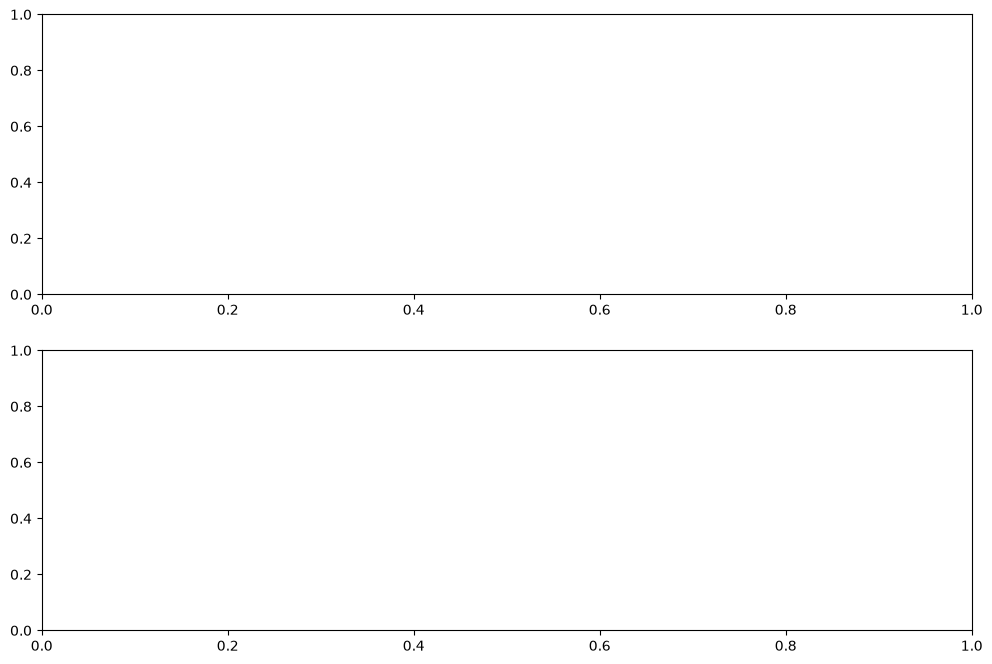

In [15]:
import matplotlib.pyplot as plt

test_dates = series.index[target_idx[test_mask]]

fig, ax = plt.subplots(2, 1, figsize=(12, 8))

ax[0].plot(test_dates, y_true, label="Gerçek", color="black", lw=1)
ax[0].plot(test_dates, y_pred, label="LSTM", color="tab:red", lw=1)
ax[0].set_title("Test seti: gerçek vs LSTM tahmini")
ax[0].legend()

ax[1].plot(history.history["loss"], label="train loss")
ax[1].plot(history.history["val_loss"], label="val loss")
ax[1].set_title("Eğitim eğrisi")
ax[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
model.save("../model/hanoi_temp_lstm.keras")